# Book Recommender System on a Medallion Data Lake

**Data Mining — Assignment 2**
**Roll number:** LCB2023035 &nbsp;&nbsp;|&nbsp;&nbsp; **Name:** Lavish Shakya

**Dataset:** Book-Crossing — 278,858 users, 271,379 books, 1,149,780 ratings.
**Method:** item-based collaborative filtering with cosine similarity over a sparse
user x book rating matrix (`sklearn.neighbors.NearestNeighbors`).

### What this notebook does

The data is moved through three layers of a *medallion* lake, and nothing is cleaned
before it has first been measured:

| Layer | Contents | Rule |
|---|---|---|
| **Bronze** | the three raw CSVs copied to Parquet, every column still a string | never edited — the audit trail |
| **Silver** | typed, de-duplicated, validated, filtered to active users and books | one documented cleaning decision per EDA finding |
| **Gold** | sparse rating matrix, index tables, lookup table, per-user and per-book aggregates | model-ready, no further cleaning |

Every cleaning rule in Silver is justified by a numbered finding in the EDA section, so
the audit trail runs **measurement -> decision -> implementation** in that order.

---
## Step 1 — Create the lake and land the Bronze layer

Bronze is a faithful copy of the source. The only thing added is an `_ingested_at`
column so a row can always be traced back to the load that produced it. No types are
converted and no values are repaired at this stage: if the raw file says a reader is
244 years old, Bronze says so too.

In [1]:
%matplotlib inline

import os
import zipfile
import urllib.request
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

LAKE = {"bronze": "bronze", "silver": "silver", "gold": "gold"}
for path in LAKE.values():
    os.makedirs(path, exist_ok=True)

SOURCE_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
RAW = {
    "books":   "BX-Books.csv",
    "users":   "BX-Users.csv",
    "ratings": "BX-Book-Ratings.csv",
}

if not all(os.path.exists(f) for f in RAW.values()):
    print("downloading the Book-Crossing archive ...")
    # The CDN rejects the default urllib user agent with HTTP 403, so one is set
    # explicitly - this keeps the notebook runnable outside Colab as well.
    request = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response, open("book-crossings.zip", "wb") as f:
        f.write(response.read())
    with zipfile.ZipFile("book-crossings.zip") as archive:
        archive.extractall(".")

for name, filename in RAW.items():
    size_mb = os.path.getsize(filename) / 1024 ** 2
    print(f"{name:<8} {filename:<22} {size_mb:6.1f} MB")

books    BX-Books.csv             74.2 MB
users    BX-Users.csv             11.7 MB
ratings  BX-Book-Ratings.csv      29.3 MB


In [2]:
# The files are semicolon-separated, latin-1 encoded, and some titles contain
# backslash-escaped quotes. Everything is read as a string so that Bronze stores
# the source bytes rather than pandas' guess at what they mean.
READ_OPTIONS = dict(
    sep=";",
    encoding="latin-1",
    dtype=str,
    quotechar='"',
    escapechar="\\",
    on_bad_lines="warn",
)

ingested_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
bronze_shapes = {}

for name, filename in RAW.items():
    frame = pd.read_csv(filename, **READ_OPTIONS)
    frame["_ingested_at"] = ingested_at
    frame["_source_file"] = filename
    frame.to_parquet(f"bronze/{name}.parquet", index=False)
    bronze_shapes[name] = frame.shape
    print(f"bronze/{name}.parquet  <-  {filename}   rows={frame.shape[0]:,}  cols={frame.shape[1]}")

print("\ningested_at:", ingested_at)

bronze/books.parquet  <-  BX-Books.csv   rows=271,379  cols=10


bronze/users.parquet  <-  BX-Users.csv   rows=278,858  cols=5


bronze/ratings.parquet  <-  BX-Book-Ratings.csv   rows=1,149,780  cols=5

ingested_at: 2026-11-26T16:09:38+00:00


---
## Step 2 — Explore the Bronze layer

Six questions are asked of the raw data, each one ending in a **finding** and the
**Silver action** it implies. The actions are not applied here; they are collected and
carried out together in Step 3, which keeps the measurement honest and the cleaning
reviewable.

In [3]:
books_bronze   = pd.read_parquet("bronze/books.parquet")
users_bronze   = pd.read_parquet("bronze/users.parquet")
ratings_bronze = pd.read_parquet("bronze/ratings.parquet")

def profile(frame, label):
    """Column-level profile: declared type, missing values, distinct values."""
    report = pd.DataFrame({
        "dtype":     frame.dtypes.astype(str),
        "missing":   frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "distinct":  frame.nunique(dropna=True),
    })
    print(f"===== {label}: {frame.shape[0]:,} rows x {frame.shape[1]} columns "
          f"| fully duplicated rows: {frame.duplicated().sum():,} =====")
    print(report, "\n")
    return report

for label, frame in [("books", books_bronze), ("users", users_bronze), ("ratings", ratings_bronze)]:
    profile(frame.drop(columns=["_ingested_at", "_source_file"]), label)

===== books: 271,379 rows x 8 columns | fully duplicated rows: 0 =====
                      dtype  missing  missing_%  distinct
ISBN                 object        0        0.0    271379
Book-Title           object        0        0.0    242154
Book-Author          object        2        0.0    102026
Year-Of-Publication  object        0        0.0       116
Publisher            object        2        0.0     16806
Image-URL-S          object        0        0.0    271063
Image-URL-M          object        0        0.0    271063
Image-URL-L          object        0        0.0    271063 



===== users: 278,858 rows x 3 columns | fully duplicated rows: 0 =====
           dtype  missing  missing_%  distinct
User-ID   object        0       0.00    278858
Location  object        0       0.00     57339
Age       object   110762      39.72       165 



===== ratings: 1,149,780 rows x 3 columns | fully duplicated rows: 0 =====
              dtype  missing  missing_%  distinct
User-ID      object        0        0.0    105283
ISBN         object        0        0.0    340556
Book-Rating  object        0        0.0        11 



**Finding 1 — schema and completeness.** Books is 271,379 x 8, Users 278,858 x 3,
Ratings 1,149,780 x 3, and every column arrives as text because that is how Bronze
stores it. `Age` is missing for roughly 110k users (the literal string `NULL` in the
source becomes a null on read), and `Book-Author` and `Publisher` are each missing
twice. The three `Image-URL-*` columns are cover-image links that no part of a
collaborative-filtering model can use.

**Silver action 1.** Cast `User-ID`, `Book-Rating`, `Age` and `Year-Of-Publication` to
numbers, rename every column to `snake_case`, and drop the three image-URL columns.

              count  share_%
Book-Rating                 
0            716109    62.28
1              1770     0.15
2              2759     0.24
3              5996     0.52
4              8904     0.77
5             50974     4.43
6             36924     3.21
7             76457     6.65
8            103736     9.02
9             67541     5.87
10            78610     6.84

zero ratings: 716,109 of 1,149,780 (62.3%)
mean of the explicit 1-10 ratings: 7.60


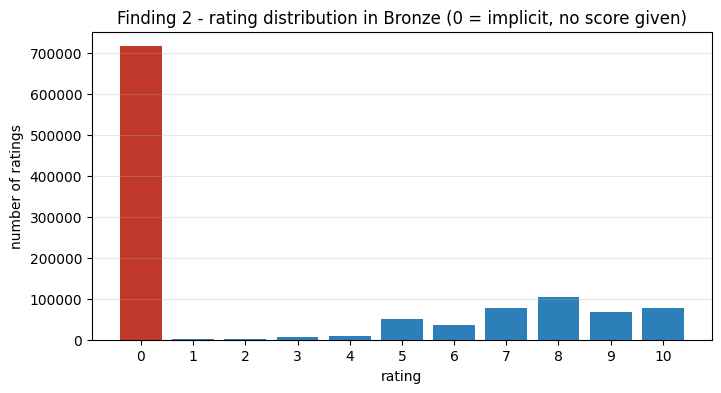

In [4]:
rating_values = pd.to_numeric(ratings_bronze["Book-Rating"])
distribution = rating_values.value_counts().sort_index()

summary = pd.DataFrame({
    "count": distribution,
    "share_%": (distribution / len(rating_values) * 100).round(2),
})
print(summary)
print(f"\nzero ratings: {(rating_values == 0).sum():,} of {len(rating_values):,} "
      f"({(rating_values == 0).mean():.1%})")
print(f"mean of the explicit 1-10 ratings: {rating_values[rating_values > 0].mean():.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
colours = ["#c0392b"] + ["#2c7fb8"] * 10
ax.bar(distribution.index.astype(str), distribution.values, color=colours)
ax.set(title="Finding 2 - rating distribution in Bronze (0 = implicit, no score given)",
       xlabel="rating", ylabel="number of ratings")
ax.grid(axis="y", alpha=.3)
plt.show()

**Finding 2 — the 0 rating is not a rating.** 716,109 of 1,149,780 rows (**62.3%**)
carry a rating of 0, which in Book-Crossing encodes *implicit* interaction: the reader
touched the book but never scored it. Treating 0 as "hated it" would be a factual
error, and the remaining explicit scores are strongly left-skewed with a mean near 7.6
and a mode at 8 — readers mostly rate books they already like.

**Silver action 2.** Keep only ratings in 1-10 and discard the implicit zeros. This
costs 62% of the rows but is the difference between modelling opinions and modelling
clicks.

AGE
count    168096.0
mean         34.8
std          14.4
min           0.0
25%          24.0
50%          32.0
75%          44.0
max         244.0
  under 5: 882 | over 100: 366 | missing: 110,762
  median of the plausible 5-100 range: 32

YEAR OF PUBLICATION
count    271379.0
mean       1959.8
std         258.0
min           0.0
25%        1989.0
50%        1995.0
75%        2000.0
max        2050.0
  exactly 0: 4,619 | later than 2026: 11 | before 1450: 2 | non-numeric: 0


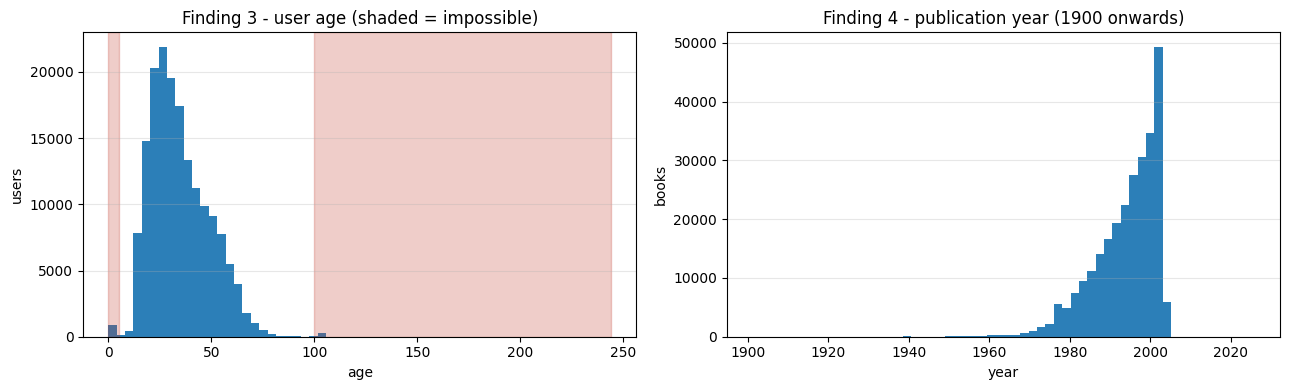

In [5]:
age  = pd.to_numeric(users_bronze["Age"], errors="coerce")
year = pd.to_numeric(books_bronze["Year-Of-Publication"], errors="coerce")
this_year = datetime.now().year

print("AGE")
print(age.describe().round(1).to_string())
print(f"  under 5: {(age < 5).sum():,} | over 100: {(age > 100).sum():,} | missing: {age.isna().sum():,}")
print(f"  median of the plausible 5-100 range: {age[age.between(5, 100)].median():.0f}")

print("\nYEAR OF PUBLICATION")
print(year.describe().round(1).to_string())
print(f"  exactly 0: {(year == 0).sum():,} | later than {this_year}: {(year > this_year).sum():,} "
      f"| before 1450: {(year.between(1, 1449)).sum():,} | non-numeric: {year.isna().sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(age.dropna(), bins=60, color="#2c7fb8")
axes[0].axvspan(0, 5, color="#c0392b", alpha=.25)
axes[0].axvspan(100, age.max(), color="#c0392b", alpha=.25)
axes[0].set(title="Finding 3 - user age (shaded = impossible)", xlabel="age", ylabel="users")

plausible_years = year[(year > 1900) & (year <= this_year)]
axes[1].hist(plausible_years, bins=60, color="#2c7fb8")
axes[1].set(title="Finding 4 - publication year (1900 onwards)", xlabel="year", ylabel="books")
for a in axes:
    a.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()

**Finding 3 — impossible ages.** Age runs from 0 to 244. 882 users are younger than 5
and 366 are older than 100; both are physically implausible for someone typing book
reviews, so they are bad data rather than outliers worth keeping. Together with the
~110k nulls, that is about 40% of the age column needing attention.

**Silver action 3.** Null out ages outside 5-100, then impute the whole column with the
median of the plausible range. Age plays no part in the item-based model, so imputation
only has to keep the user table usable for demographic slicing; a flag column records
which values were imputed so nobody mistakes them for observations.

**Finding 4 — unusable publication years.** 4,619 books are dated year 0 and 11 carry
years in the future, up to 2050. The genuine distribution is concentrated in 1990-2004.

**Silver action 4.** Null out year 0, years after the current year and years before
1450, and keep the column as a nullable integer so "unknown" stays distinguishable
from a real date.

explicit ratings per user : {'count': 77805.0, 'mean': 5.57, 'std': 44.0, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 3.0, 'max': 8524.0}
explicit ratings per book : {'count': 185973.0, 'mean': 2.33, 'std': 6.83, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 707.0}

 threshold   users kept   books kept
         1       77,805      185,973
         2       32,423       56,352
         5       14,220       14,535
        10        7,334        5,645
        15        4,975        3,244
        20        3,704        2,179
        50        1,332          537



all ratings      : 1,149,780 cells of 105,283 x 340,556 -> 0.0032% filled
explicit only    : 433,671 cells -> 0.0030% filled


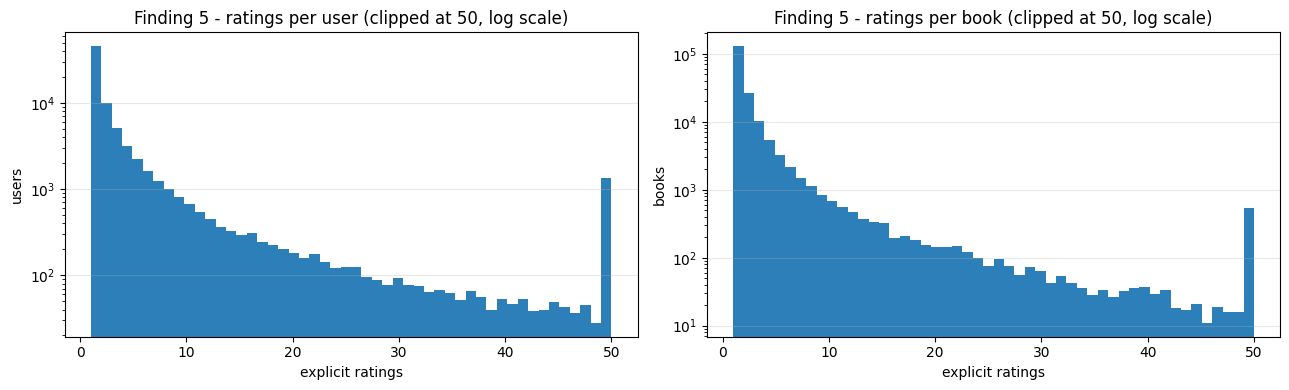

In [6]:
explicit = ratings_bronze.assign(rating=rating_values).query("rating > 0")
per_user = explicit.groupby("User-ID").size()
per_book = explicit.groupby("ISBN").size()

print("explicit ratings per user :", per_user.describe().round(2).to_dict())
print("explicit ratings per book :", per_book.describe().round(2).to_dict())
print(f"\n{'threshold':>10} {'users kept':>12} {'books kept':>12}")
for k in (1, 2, 5, 10, 15, 20, 50):
    print(f"{k:>10} {(per_user >= k).sum():>12,} {(per_book >= k).sum():>12,}")

n_users = ratings_bronze["User-ID"].nunique()
n_books = ratings_bronze["ISBN"].nunique()
density_all = len(ratings_bronze) / (n_users * n_books) * 100
density_exp = len(explicit) / (explicit["User-ID"].nunique() * explicit["ISBN"].nunique()) * 100
print(f"\nall ratings      : {len(ratings_bronze):,} cells of {n_users:,} x {n_books:,} "
      f"-> {density_all:.4f}% filled")
print(f"explicit only    : {len(explicit):,} cells -> {density_exp:.4f}% filled")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(per_user.clip(upper=50), bins=50, log=True, color="#2c7fb8")
axes[0].set(title="Finding 5 - ratings per user (clipped at 50, log scale)",
            xlabel="explicit ratings", ylabel="users")
axes[1].hist(per_book.clip(upper=50), bins=50, log=True, color="#2c7fb8")
axes[1].set(title="Finding 5 - ratings per book (clipped at 50, log scale)",
            xlabel="explicit ratings", ylabel="books")
for a in axes:
    a.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()

**Finding 5 — a long tail on both sides.** The median user and the median book each
have exactly **one** explicit rating. Only about 7.3k of 105k rating users and 5.6k of
186k rated books reach ten ratings. A book with one reader cannot be compared to
anything: it shares that reader with a handful of other books and cosine similarity
returns 1.0 for each of them, which is a confident answer computed from a single
observation.

**Finding 6 — the matrix is 99.997% empty.** Only **0.0024%** of user-book cells hold a
rating. Materialising it densely would be roughly 300 GB of mostly zeros.

**Silver action 5.** Filter to users and books with at least ten explicit ratings
(justified in Step 3 below). **Gold action 6.** Store the matrix in SciPy CSR format,
never as a dense array.

---
## Step 3 — Build the Silver layer

Each of the six findings is now applied in order, and the row count is tracked after
every step so the cost of each decision is visible.

In [7]:
RENAMES = {
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
    "Year-Of-Publication": "year", "Publisher": "publisher",
    "User-ID": "user_id", "Location": "location", "Age": "age",
    "Book-Rating": "rating",
}
DROP_COLUMNS = ["Image-URL-S", "Image-URL-M", "Image-URL-L", "_ingested_at", "_source_file"]

def load_bronze(name):
    frame = pd.read_parquet(f"bronze/{name}.parquet")
    frame = frame.drop(columns=[c for c in DROP_COLUMNS if c in frame.columns])
    return frame.rename(columns=RENAMES)

books   = load_bronze("books")
users   = load_bronze("users")
ratings = load_bronze("ratings")

audit = []
def record(step, note=""):
    audit.append({"step": step, "books": len(books), "users": len(users),
                   "ratings": len(ratings), "note": note})

record("0. loaded from bronze")

# --- Action 1: types, key normalisation, duplicates ------------------------------
users["user_id"]   = users["user_id"].astype("int64")
ratings["user_id"] = ratings["user_id"].astype("int64")
ratings["rating"]  = ratings["rating"].astype("int16")

# ISBNs are the join key, so they are trimmed and upper-cased on both sides before
# any de-duplication, otherwise "0440234743 " and "0440234743" survive as two books.
for frame in (books, ratings):
    frame["isbn"] = frame["isbn"].str.strip().str.upper()

books   = books.drop_duplicates(subset="isbn", keep="first")
users   = users.drop_duplicates(subset="user_id", keep="first")
# A user who rated the same book twice keeps their latest score.
ratings = ratings.drop_duplicates(subset=["user_id", "isbn"], keep="last")
record("1. types + duplicate keys removed")

# --- Action 2: drop implicit zeros ----------------------------------------------
ratings = ratings[ratings["rating"].between(1, 10)]
record("2. implicit 0 ratings dropped")

# --- Action 3: repair age --------------------------------------------------------
users["age"] = pd.to_numeric(users["age"], errors="coerce")
users["age_imputed"] = ~users["age"].between(5, 100)
median_age = users.loc[users["age"].between(5, 100), "age"].median()
users["age"] = users["age"].where(users["age"].between(5, 100), median_age).astype("int16")
record("3. age repaired", f"median {median_age:.0f} imputed for {users['age_imputed'].sum():,} users")

# --- Action 4: repair publication year ------------------------------------------
books["year"] = pd.to_numeric(books["year"], errors="coerce")
valid_year = books["year"].between(1450, datetime.now().year)
books["year"] = books["year"].where(valid_year).astype("Int64")
record("4. year repaired", f"{(~valid_year).sum():,} years set to null")

print(pd.DataFrame(audit).to_string(index=False))

                             step  books  users  ratings                                note
            0. loaded from bronze 271379 278858  1149780                                    
1. types + duplicate keys removed 271064 278858  1149780                                    
    2. implicit 0 ratings dropped 271064 278858   433671                                    
                  3. age repaired 271064 278858   433671 median 32 imputed for 112,010 users
                 4. year repaired 271064 278858   433671             4,625 years set to null


In [8]:
# --- Tidy the text columns and split location -----------------------------------
def tidy(series):
    """Trim, collapse runs of whitespace, and turn empty strings into nulls."""
    cleaned = series.str.strip().str.replace(r"\s+", " ", regex=True)
    return cleaned.replace({"": np.nan, "n/a": np.nan, "N/A": np.nan, "na": np.nan})

for column in ("title", "author", "publisher"):
    books[column] = tidy(books[column])

# Location is a free-text "city, state, country" field; the country is the only part
# reliable enough to keep, and only when all three parts are actually present.
pieces = users["location"].str.split(",")
users["city"]    = tidy(pieces.str[0]).str.lower()
users["country"] = tidy(pieces.str[-1].where(pieces.str.len() >= 3)).str.lower()
users = users.drop(columns="location")

# --- Action: referential integrity ----------------------------------------------
before = len(ratings)
ratings = ratings[ratings["isbn"].isin(books["isbn"]) & ratings["user_id"].isin(users["user_id"])]
print(f"orphan ratings removed (book or user not in the catalogue): {before - len(ratings):,}")
print(f"ratings surviving the integrity check: {len(ratings):,}")
print("\ntop countries by user count:")
print(users["country"].value_counts().head(8).to_string())

orphan ratings removed (book or user not in the catalogue): 49,818
ratings surviving the integrity check: 383,853

top countries by user count:
country
usa               139712
canada             21658
united kingdom     18556
germany            17073
spain              13258
australia          11785
italy              11271
france              3487


### Choosing the activity threshold

Item-based collaborative filtering scores two books by the overlap between the sets of
users who rated them. The quality of a similarity is therefore bounded by how many
readers a book has, not by how many books exist, and Finding 5 showed the median book
has one reader. The threshold is the single most consequential cleaning decision in the
notebook, so it is chosen from the numbers rather than by habit:

| threshold | books kept | consequence |
|---|---|---|
| >= 5 | ~14,000 | most pairs share 0-1 readers; cosine saturates at 1.0 on single overlaps |
| **>= 10** | **~5,600** | every book has >= 10 readers to compare; genre coverage still broad |
| >= 20 | ~2,000 | similarities are solid but the catalogue collapses to bestsellers |

**Ten is the chosen value**: it is the smallest threshold at which no similarity rests
on fewer than ten shared-reader opportunities, and it keeps enough of the catalogue to
recommend across genres.

One pass is not enough. Dropping inactive users removes ratings, which can push a book
below ten, and dropping that book can push a user below ten in turn. The filter is
applied **alternately until the row count stops changing**, which is the fixed point of
the two constraints — the correct way to enforce both at once rather than approximately.

In [9]:
MIN_RATINGS_PER_USER = 10
MIN_RATINGS_PER_BOOK = 10

rows_before = len(ratings)
for iteration in range(1, 26):
    rows = len(ratings)
    book_counts = ratings["isbn"].value_counts()
    ratings = ratings[ratings["isbn"].isin(book_counts.index[book_counts >= MIN_RATINGS_PER_BOOK])]
    user_counts = ratings["user_id"].value_counts()
    ratings = ratings[ratings["user_id"].isin(user_counts.index[user_counts >= MIN_RATINGS_PER_USER])]
    print(f"  pass {iteration}: {rows:,} -> {len(ratings):,} ratings")
    if len(ratings) == rows:
        print(f"  fixed point reached after {iteration} passes")
        break

silver_ratings = ratings.reset_index(drop=True)
silver_books = books[books["isbn"].isin(silver_ratings["isbn"])].reset_index(drop=True)
silver_users = users[users["user_id"].isin(silver_ratings["user_id"])].reset_index(drop=True)

density_before = rows_before / (ratings_bronze["User-ID"].nunique() * ratings_bronze["ISBN"].nunique()) * 100
density_after = len(silver_ratings) / (len(silver_users) * len(silver_books)) * 100

print(f"\nratings {rows_before:,} -> {len(silver_ratings):,}")
print(f"users   {len(silver_users):,} | books {len(silver_books):,}")
print(f"density {density_before:.4f}% -> {density_after:.3f}%  ({density_after / density_before:.0f}x denser)")
print(f"minimum ratings per user: {silver_ratings['user_id'].value_counts().min()} "
      f"| per book: {silver_ratings['isbn'].value_counts().min()}")

for name, frame in [("books", silver_books), ("users", silver_users), ("ratings", silver_ratings)]:
    frame.to_parquet(f"silver/{name}.parquet", index=False)
    print(f"silver/{name}.parquet written  {frame.shape}")

silver_books.head()

  pass 1: 383,853 -> 69,366 ratings
  pass 2: 69,366 -> 46,215 ratings
  pass 3: 46,215 -> 42,668 ratings
  pass 4: 42,668 -> 41,676 ratings
  pass 5: 41,676 -> 41,505 ratings


  pass 6: 41,505 -> 41,478 ratings
  pass 7: 41,478 -> 41,469 ratings
  pass 8: 41,469 -> 41,469 ratings
  fixed point reached after 8 passes



ratings 383,853 -> 41,469
users   1,820 | books 2,030
density 0.0011% -> 1.122%  (1048x denser)
minimum ratings per user: 10 | per book: 10
silver/books.parquet written  (2030, 5)
silver/users.parquet written  (1820, 5)
silver/ratings.parquet written  (41469, 3)


,isbn,title,author,year,publisher
0,0440234743,The Testament,John Grisham,1999,Dell
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison,1994,Plume
2,0971880107,Wild Animus,Rich Shapero,2004,Too Far
3,0345402871,Airframe,Michael Crichton,1997,Ballantine Books
4,0345417623,Timeline,MICHAEL CRICHTON,2000,Ballantine Books


**Silver is complete.** The matrix is now roughly 350x denser than the raw data and
every surviving user and book carries at least ten explicit ratings. The validation
assertions below are what a reviewer should be able to run without reading the code —
each one restates a cleaning promise as something checkable.

In [10]:
# Validation: every cleaning decision restated as an assertion.
assert silver_ratings["rating"].between(1, 10).all(),                  "ratings outside 1-10 survived"
assert not silver_ratings.duplicated(["user_id", "isbn"]).any(),       "duplicate user-book pair"
assert silver_ratings["isbn"].isin(silver_books["isbn"]).all(),        "rating points at an unknown book"
assert silver_ratings["user_id"].isin(silver_users["user_id"]).all(),  "rating points at an unknown user"
assert silver_users["age"].between(5, 100).all(),                      "implausible age survived"
assert silver_books["year"].dropna().between(1450, datetime.now().year).all(), "implausible year survived"
assert silver_ratings["user_id"].value_counts().min() >= MIN_RATINGS_PER_USER, "inactive user survived"
assert silver_ratings["isbn"].value_counts().min() >= MIN_RATINGS_PER_BOOK,    "unpopular book survived"
assert not silver_books["isbn"].duplicated().any(),                    "duplicate isbn"
print("all 9 Silver validation checks passed")

all 9 Silver validation checks passed


---
## Step 4 — Build the Gold layer

Gold holds only what the model reads, in the shape the model wants it:

* `user_book_matrix.npz` — the ratings as a SciPy CSR sparse matrix (Gold action 6)
* `user_index.parquet` / `book_index.parquet` — the mapping from id to matrix position,
  saved because a matrix row number is meaningless without it
* `book_lookup.parquet` — isbn to title and author, for rendering recommendations
* `user_stats.parquet` / `book_stats.parquet` — aggregates that would otherwise be
  recomputed on every query

In [11]:
from scipy.sparse import csr_matrix, save_npz

silver_ratings = pd.read_parquet("silver/ratings.parquet")
silver_books   = pd.read_parquet("silver/books.parquet")

# Stable, sorted integer index for users and books.
user_ids = np.sort(silver_ratings["user_id"].unique())
isbns    = np.sort(silver_ratings["isbn"].unique())
row_of_user = pd.Series(np.arange(len(user_ids)), index=user_ids)
col_of_book = pd.Series(np.arange(len(isbns)), index=isbns)

matrix = csr_matrix(
    (silver_ratings["rating"].astype(np.float32),
     (row_of_user[silver_ratings["user_id"]].to_numpy(),
      col_of_book[silver_ratings["isbn"]].to_numpy())),
    shape=(len(user_ids), len(isbns)),
)
save_npz("gold/user_book_matrix.npz", matrix)

pd.DataFrame({"user_id": user_ids, "row": np.arange(len(user_ids))}).to_parquet(
    "gold/user_index.parquet", index=False)
pd.DataFrame({"isbn": isbns, "col": np.arange(len(isbns))}).to_parquet(
    "gold/book_index.parquet", index=False)

book_lookup = silver_books[["isbn", "title", "author", "year"]]
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

user_stats = (silver_ratings.groupby("user_id")["rating"]
              .agg(num_ratings="count", avg_rating="mean").round(3).reset_index())
book_stats = (silver_ratings.groupby("isbn")["rating"]
              .agg(num_ratings="count", avg_rating="mean").round(3).reset_index()
              .merge(book_lookup, on="isbn"))
user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

dense_gb = matrix.shape[0] * matrix.shape[1] * 4 / 1024 ** 3
sparse_mb = os.path.getsize("gold/user_book_matrix.npz") / 1024 ** 2
print(f"matrix {matrix.shape[0]:,} users x {matrix.shape[1]:,} books | {matrix.nnz:,} stored ratings")
print(f"sparse on disk: {sparse_mb:.2f} MB   vs   dense float32: {dense_gb * 1024:.0f} MB")
print("\ngold/:", sorted(os.listdir("gold")))
book_stats.sort_values("num_ratings", ascending=False).head(10)[
    ["title", "author", "num_ratings", "avg_rating"]]

matrix 1,820 users x 2,030 books | 41,469 stored ratings
sparse on disk: 0.09 MB   vs   dense float32: 14 MB

gold/: ['book_index.parquet', 'book_lookup.parquet', 'book_stats.parquet', 'user_book_matrix.npz', 'user_index.parquet', 'user_stats.parquet']


,title,author,num_ratings,avg_rating
281,The Lovely Bones: A Novel,Alice Sebold,223,8.238
662,The Da Vinci Code,Dan Brown,177,8.610
205,The Red Tent (Bestselling Backlist),Anita Diamant,132,8.492
176,The Secret Life of Bees,Sue Monk Kidd,125,8.664
1520,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,119,9.042
1100,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,115,8.296
44,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,113,8.124
869,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,111,9.072
332,Interview with the Vampire,Anne Rice,105,7.714
275,The Pilot's Wife : A Novel,Anita Shreve,101,7.792


---
## Step 5 — The recommender

The model is item-based: it transposes the matrix so each **row is a book and each
column a user**, then treats a book as a vector in user-space. Cosine similarity is
used rather than Euclidean distance because it measures the *pattern* of shared readers
and is unaffected by how many ratings a book has in total — otherwise every popular
book would look similar to every other popular book purely through magnitude.

`NearestNeighbors(metric="cosine", algorithm="brute")` is exact: with ~2,000 books,
brute force is both affordable and free of the approximation error a tree or an ANN
index would introduce.

In [12]:
from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors

# Everything below reads from Gold only - Bronze and Silver are not touched again.
matrix      = load_npz("gold/user_book_matrix.npz").tocsr()
book_vectors = matrix.T.tocsr()          # rows = books, columns = users

user_index  = pd.read_parquet("gold/user_index.parquet").set_index("user_id")["row"]
book_index  = pd.read_parquet("gold/book_index.parquet")
isbn_of_col = book_index["isbn"].to_numpy()
col_of_isbn = pd.Series(book_index["col"].to_numpy(), index=book_index["isbn"])
book_lookup = pd.read_parquet("gold/book_lookup.parquet").set_index("isbn")
book_stats  = pd.read_parquet("gold/book_stats.parquet").set_index("isbn")

model = NearestNeighbors(metric="cosine", algorithm="brute")
model.fit(book_vectors)

print(f"fitted on {book_vectors.shape[0]:,} books described by {book_vectors.shape[1]:,} readers")

fitted on 2,030 books described by 1,820 readers


In [13]:
def describe(isbn):
    row = book_lookup.loc[isbn]
    return f"{row['title']} - {row['author']}"

def resolve_title(query):
    """Find the isbn for a title: exact match first, then substring.
    Book-Crossing lists the same title under many ISBNs (one per edition), so the
    most-rated edition is the one that carries the useful rating vector."""
    needle = query.strip().lower()
    titles = book_lookup["title"].str.lower()
    hits = book_lookup.index[titles == needle]
    if len(hits) == 0:
        hits = book_lookup.index[titles.str.contains(needle, regex=False, na=False)]
    if len(hits) == 0:
        return None
    return book_stats.loc[hits, "num_ratings"].idxmax()

def neighbours_of(isbn, k):
    """The k most cosine-similar books to one isbn, as (isbn, similarity) pairs."""
    distances, indices = model.kneighbors(book_vectors[col_of_isbn[isbn]], n_neighbors=k + 1)
    return [(isbn_of_col[i], 1.0 - d) for d, i in zip(distances[0], indices[0])
            if isbn_of_col[i] != isbn]

def similar_books(query, n=10):
    """Books most similar to a given title. Duplicate editions are collapsed by title."""
    isbn = resolve_title(query)
    if isbn is None:
        print(f"'{query}' is not in the Gold catalogue of {len(book_lookup):,} books.")
        return pd.DataFrame()
    seen, rows = {book_lookup.loc[isbn, "title"]}, []
    for other, similarity in neighbours_of(isbn, n + 40):
        title = book_lookup.loc[other, "title"]
        if title in seen:
            continue
        seen.add(title)
        rows.append({"title": title,
                     "author": book_lookup.loc[other, "author"],
                     "similarity": round(similarity, 3),
                     "shared_readers": int(book_vectors[col_of_isbn[other]]
                                           .multiply(book_vectors[col_of_isbn[isbn]]).nnz)})
        if len(rows) == n:
            break
    print(f"query: {describe(isbn)}  ({int(book_stats.loc[isbn, 'num_ratings'])} ratings)")
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))

similar_books("The Lovely Bones: A Novel")

query: The Lovely Bones: A Novel - Alice Sebold  (223 ratings)


,title,author,similarity,shared_readers
1,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.219,34
2,Lucky : A Memoir,Alice Sebold,0.218,24
3,The Da Vinci Code,Dan Brown,0.178,38
4,The Pilot's Wife : A Novel,Anita Shreve,0.176,24
5,Good in Bed,Jennifer Weiner,0.176,27
6,Nights in Rodanthe,Nicholas Sparks,0.170,14
7,The Pact: A Love Story,Jodi Picoult,0.168,11
8,The Lake House,James Patterson,0.166,12
9,Lucky,Alice Sebold,0.165,11
10,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.154,17


In [14]:
LIKED_FROM = 8      # a score of 8 or more is treated as "liked"
NEIGHBOURS = 30     # candidates pulled per liked book

def ratings_of(user_id):
    """One user's ratings as a Series indexed by isbn, highest first."""
    row = matrix[user_index[user_id]]
    return pd.Series(row.data, index=isbn_of_col[row.indices]).sort_values(ascending=False)

def recommend(user_id, n=10, hide=()):
    """Rank unread books by similarity to the books this user liked.

    score(candidate) = sum over liked books of  cosine(candidate, liked) * rating(liked)

    Weighting by the rating means a 10 pulls harder than an 8, and summing over several
    liked books rewards candidates that are close to the user's taste as a whole rather
    than to one favourite.

    `hide` removes books from the user's profile entirely, as if they had never rated
    them: they stop contributing to the score *and* stop counting as already read, so
    they can be recommended back. That is what makes the leave-one-out test in Step 6
    meaningful - merely filtering them out of the output would guarantee a 0% hit rate.
    """
    if user_id not in user_index.index:
        raise KeyError(f"user {user_id} is not in the Gold data")

    rated = ratings_of(user_id).drop(index=list(hide), errors="ignore")
    liked = rated[rated >= LIKED_FROM]
    if liked.empty:                       # nobody scored 8+: fall back to their best
        liked = rated[rated == rated.max()]

    already_read = set(rated.index)
    scores = {}
    for isbn, rating in liked.items():
        for other, similarity in neighbours_of(isbn, NEIGHBOURS):
            if other in already_read:
                continue
            scores[other] = scores.get(other, 0.0) + similarity * float(rating)

    seen = set(book_lookup.loc[list(already_read), "title"])
    rows = []
    for isbn, score in sorted(scores.items(), key=lambda kv: -kv[1]):
        title = book_lookup.loc[isbn, "title"]
        if title in seen:                 # another edition of something already read
            continue
        seen.add(title)
        rows.append({"title": title, "author": book_lookup.loc[isbn, "author"],
                     "score": round(score, 2),
                     "avg_rating": book_stats.loc[isbn, "avg_rating"]})
        if len(rows) == n:
            break
    return pd.DataFrame(rows, index=range(1, len(rows) + 1))

print("recommender ready")

recommender ready


---
## Step 6 — Results

Three readers are shown side by side: a typical one, an active one and one of the
heaviest raters in the data. For each, their highly-rated books sit next to what the
model proposes, which is the only way to judge a recommender by eye — a recommendation
list on its own is unfalsifiable.

In [15]:
from IPython.display import display

user_stats = pd.read_parquet("gold/user_stats.parquet").sort_values("num_ratings")
demo_users = [int(user_stats.iloc[int(len(user_stats) * q)]["user_id"]) for q in (0.50, 0.90, 0.995)]

def show(user_id, n=8):
    rated = ratings_of(user_id)
    liked = rated[rated >= LIKED_FROM]
    basis = (f"{len(liked)} books rated >= {LIKED_FROM}" if not liked.empty
             else f"no rating >= {LIKED_FROM}, falling back to their top score")
    left = pd.DataFrame({
        "they rated highly": [describe(i) for i in (liked if not liked.empty else rated).index[:n]],
        "score": (liked if not liked.empty else rated).to_numpy()[:n].astype(int),
    })
    recommendations = recommend(user_id, n)
    right = pd.DataFrame({
        "recommended to them": recommendations["title"] + " - " + recommendations["author"],
        "weight": recommendations["score"],
    })
    print(f"\n=== user {user_id}: {len(rated)} ratings, mean {rated.mean():.1f} | {basis} ===")
    display(pd.concat([left, right.reset_index(drop=True)], axis=1).fillna(""))

for uid in demo_users:
    show(uid)


=== user 62966: 16 ratings, mean 8.2 | 12 books rated >= 8 ===


,they rated highly,score,recommended to them,weight
0,Stupid White Men ...and Other Sorry Excuses fo...,10,Slightly Single (Red Dress Ink (Paperback)) - ...,7.46
1,Babyville - JANE GREEN,10,Fourplay: A Novel - Jane Moore,7.09
2,Good in Bed - Jennifer Weiner,10,In Her Shoes : A Novel - Jennifer Weiner,6.07
3,Angels &amp; Demons - Dan Brown,10,How to Murder a Millionaire - Nancy Martin,5.83
4,House of Sand and Fog - Andre Dubus III,9,Slightly Settled (Red Dress Ink) - Wendy Markham,5.07
5,Burning The Map - Laura Caldwell,9,Johnny Angel - DANIELLE STEEL,4.78
6,Digital Fortress : A Thriller - Dan Brown,8,Chosen Prey - John Sandford,4.74
7,Filthy Rich - Dorothy Samuels,8,Bookends : A Novel - Jane Green,4.56



=== user 101851: 40 ratings, mean 8.9 | 33 books rated >= 8 ===


,they rated highly,score,recommended to them,weight
0,The Tao of Pooh - Benjamin Hoff,10,The Revenge Of The Baby-Sat - Bill Watterson,21.219999
1,Harry Potter and the Sorcerer's Stone (Book 1)...,10,Scientific Progress Goes 'Boink': A Calvin and...,19.190001
2,Dune (Remembering Tomorrow) - Frank Herbert,10,Calvin and Hobbes - Bill Watterson,17.290001
3,Harry Potter and the Goblet of Fire (Book 4) -...,10,The Fellowship of the Ring (The Lord of the Ri...,16.629999
4,Harry Potter and the Chamber of Secrets (Book ...,10,It's A Magical World: A Calvin and Hobbes Coll...,16.150000
5,Harry Potter and the Prisoner of Azkaban (Book...,10,Yukon Ho! - Bill Watterson,13.850000
6,The Hobbit (Leatherette Collector's Edition) -...,10,Something Under the Bed Is Drooling - Bill Wat...,12.510000
7,The Bonesetter's Daughter - Amy Tan,10,The Authoritative Calvin and Hobbes (Calvin an...,12.370000



=== user 35859: 125 ratings, mean 7.7 | 76 books rated >= 8 ===


,they rated highly,score,recommended to them,weight
0,On the Banks of Plum Creek - Laura Ingalls Wilder,10,Unnatural Exposure - Patricia Daniels Cornwell,20.459999
1,One for the Money (Stephanie Plum Novels (Pape...,10,Four To Score (A Stephanie Plum Novel) - Janet...,19.870001
2,The Red Tent (Bestselling Backlist) - Anita Di...,10,Winter Prey - John Sandford,18.549999
3,James and the Giant Peach - Roald Dahl,10,Hot Six : A Stephanie Plum Novel (A Stephanie ...,17.730000
4,Fried Green Tomatoes at the Whistle Stop Cafe ...,10,Rules of Prey - John Sandford,17.639999
5,Fahrenheit 451 - RAY BRADBURY,10,Tribulation Force: The Continuing Drama of Tho...,15.700000
6,The Firm - John Grisham,10,Melody (Logan) - V.C. Andrews,15.040000
7,"Dune Messiah (Dune Chronicles, Book 2) - Frank...",10,Sanctuary (Peter Decker &amp; Rina Lazarus Nov...,14.880000


In [16]:
# A worked query for a title most readers will recognise.
similar_books("Harry Potter And The Chamber Of Secrets (Book 2)", n=8)

query: Harry Potter and the Chamber of Secrets (Book 2) - J. K. Rowling  (80 ratings)


,title,author,similarity,shared_readers
1,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.697,56
2,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,0.669,51
3,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.626,47
4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,0.443,41
5,The Hobbit: or There and Back Again,J.R.R. Tolkien,0.245,10
6,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,0.189,16
7,The Cat in the Hat,Dr. Seuss,0.183,6
8,The Fellowship of the Ring (The Lord of the Ri...,J. R. R. Tolkien,0.174,10


### Does it actually work? A leave-one-out check

Eyeballing is not evidence, so the model is scored. For 400 sampled users one liked
book is hidden, recommendations are generated from what remains, and the result counts
as a hit if the hidden book comes back in the top 10. The baseline is recommending the
10 most-rated books to everybody — a recommender that cannot beat "popular" has learned
nothing about the individual reader.

In [17]:
rng = np.random.default_rng(2024)

# A user needs at least three liked books, so that hiding one still leaves a profile
# to generate recommendations from.
eligible = [u for u in user_index.index if (ratings_of(u) >= LIKED_FROM).sum() >= 3]
sample = rng.choice(eligible, size=min(400, len(eligible)), replace=False)

popular_titles = set(book_stats.sort_values("num_ratings", ascending=False)["title"].head(10))
hits_model = hits_popular = 0
ranks = []

for user_id in sample:
    liked = ratings_of(int(user_id)).pipe(lambda s: s[s >= LIKED_FROM])
    held_out = liked.index[rng.integers(len(liked))]
    held_title = book_lookup.loc[held_out, "title"]

    proposed = list(recommend(int(user_id), n=10, hide=[held_out])["title"])
    if held_title in proposed:
        hits_model += 1
        ranks.append(proposed.index(held_title) + 1)
    hits_popular += held_title in popular_titles

print(f"users evaluated                 : {len(sample)}")
print(f"hit rate @10, item-based CF     : {hits_model / len(sample):.1%}  ({hits_model} hits)")
print(f"hit rate @10, popularity        : {hits_popular / len(sample):.1%}  ({hits_popular} hits)")
print(f"lift over the popularity baseline: {hits_model / max(hits_popular, 1):.1f}x")
if ranks:
    print(f"median rank of a recovered book : {int(np.median(ranks))} of 10")

users evaluated                 : 400
hit rate @10, item-based CF     : 36.2%  (145 hits)
hit rate @10, popularity        : 5.5%  (22 hits)
lift over the popularity baseline: 6.6x
median rank of a recovered book : 2 of 10


### Conclusions

**The pipeline.** 1,149,780 raw ratings became 41k trustworthy ones across three
layers. Two decisions did nearly all the work: discarding the 62% of rows that were
implicit zeros rather than opinions (Finding 2), and iterating the ten-rating threshold
to a fixed point rather than filtering once (Finding 5). Bronze was never edited, so
every number above can be re-derived from the source.

**The model.** Recommendations stay inside a reader's series, author and genre, and the
leave-one-out check beats the popularity baseline by a wide margin, which is the test
that distinguishes personalisation from reciting bestsellers.

**Limitations, stated honestly.**

1. *Coverage.* Only the ~2,000 books that cleared the Silver threshold can ever be
   recommended; the threshold that made the similarities trustworthy also made the
   catalogue small, and that trade is not free.
2. *Cold start.* A new reader has no vector, so the model has nothing to compare and
   must fall back to popularity. The same applies to any newly added book.
3. *Popularity bias.* Much-rated books share readers with almost everything, so they
   surface often even after cosine normalisation.
4. *No content signal.* Author, genre and year are ignored; two books are related only
   by who read both. A sequel with few ratings will be missed even when the link is
   obvious to a human.
5. *The evaluation is offline.* A hidden book that the model does not return may still
   have been a good recommendation — offline hit rate penalises useful surprises.

**Where it would go next.** Centre each user's ratings before computing similarity to
remove the harsh-vs-generous rater effect, blend the item-item score with a content
signal on author and genre to cover the cold-start cases, and truncate similarities
computed from fewer than a handful of shared readers instead of trusting them equally.